In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import netCDF4 as nc
from netCDF4 import Dataset
import dask
import scipy
import skimage
import glob
from tqdm import tqdm
import datetime
from shapely.geometry import Point, Polygon
import concurrent.futures
import pytz
from scipy.ndimage import gaussian_filter

import warnings
warnings.filterwarnings("ignore")

import argparse
import os

from xarray.backends import BackendEntrypoint

from detect_plumes import detect_single_plume, detect_single_plume1
from launches import *
from utils import *
from tempo import *
from emissions import *

import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from matplotlib.axes import Axes
from cartopy.mpl.geoaxes import GeoAxes
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from cartopy.feature import NaturalEarthFeature
import cartopy.io.img_tiles as cimgt
GeoAxes._pcolormesh_patched = Axes.pcolormesh

import warnings
warnings.filterwarnings("ignore")
import argparse
import os
import imageio

import seaborn as sns
import tol_colors as tc

%matplotlib inline

ERROR 1: PROJ: proj_create_from_database: Open of /home/jpalmo/.conda/envs/earthdata/share/proj failed


In [2]:
from tempo import TEMPOBackendEntrypoint_L2

In [3]:
# load launches
tempo_df = get_launch_df()
tempo_df = tempo_df.loc['2023-08-01':]

# load GEOS-CF
geoscf_ds = load_geoscf()

In [4]:
geoscf_ds = geoscf_ds.isel(
    time=~geoscf_ds.indexes['time'].duplicated()
)
geoscf_ds = geoscf_ds.sortby('time')

In [5]:
tc.tol_cmap()

('sunset_discrete',
 'sunset',
 'nightfall_discrete',
 'nightfall',
 'BuRd_discrete',
 'BuRd',
 'PRGn_discrete',
 'PRGn',
 'YlOrBr_discrete',
 'YlOrBr',
 'WhOrBr',
 'iridescent',
 'rainbow_PuRd',
 'rainbow_PuBr',
 'rainbow_WhRd',
 'rainbow_WhBr',
 'rainbow_discrete')

In [6]:
# row = tempo_df["2023-11-11":"2023-11-11"]
row = tempo_df["2023-09-10":"2023-09-10"]

In [7]:
row.index[0]

Timestamp('2023-09-10 12:47:00')

In [8]:
tempodata_launch_time = row.index[0].ceil('H')
launch_time = row.index[0]
launch_lat = row['lat'].values[0]
launch_lon = row['lon'].values[0]

### L2

In [9]:
def find_file_for_time(time, product="AODALH", version="V01",
                       base="/home/jpalmo/fs09/Datasets/TEMPO"):

    t = np.datetime64(time)
    date = str(t)[:10].replace("-", "")
    stamp = str(t).replace("-", "").replace(":", "")[:15] + "Z"

    folder = f"{base}/{version}/L2/{product}"
    if product == "AODALH":
        folder += f"/{date}"

    files = glob(f"{folder}/*{stamp}*.nc")
    if not files:
        raise FileNotFoundError(stamp)

    return files[0]

In [10]:
base = "/home/jpalmo/fs09/Datasets/TEMPO"
product = "NO2"
version = "V04"

In [11]:
# special observation files
test_files = glob.glob(f"{base}/{version}/L2/{product}/*20260401*G01.nc")
test_files.sort()

In [12]:
raw_ds = xr.open_mfdataset(test_files, group='product', engine=TEMPOBackendEntrypoint_L2, combine="nested", concat_dim="time")

In [13]:
bounding_box = (launch_lon - 1, launch_lon + 1, launch_lat - 1, launch_lat + 1)
lon_min, lon_max, lat_min, lat_max = bounding_box

# limit the dataset to the bounding box, and subtract the 10th percentile to get enhancements
ds = mask_and_trim_to_roi(raw_ds, bounding_box)

In [14]:
ds

<xarray.Dataset> Size: 204MB
Dimensions:                                  (time: 25, y: 42, x: 124,
                                              corner: 4, lev: 72)
Coordinates:
  * y                                        (y) int64 336B 59 60 61 ... 99 100
  * x                                        (x) int64 992B 1252 1253 ... 1375
  * lev                                      (lev) int64 576B 1 2 3 ... 70 71 72
  * corner                                   (corner) int64 32B 0 1 2 3
    latitude                                 (time, y, x) float32 521kB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
    longitude                                (time, y, x) float32 521kB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
  * time                                     (time) datetime64[s] 200B 2026-0...
    lat_time                                 (time, y) datetime64[ns] 8kB dask.array<chunksize=(1, 42), meta=np.ndarray>
    pixel_area                               (time, y, x) float32 521kB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
Data variables: (12/23)
    lat_bounds                               (time, y, x, corner) float32 2MB dask.array<chunksize=(1, 42, 124, 4), meta=np.ndarray>
    lon_bounds                               (time, y, x, corner) float32 2MB dask.array<chunksize=(1, 42, 124, 4), meta=np.ndarray>
    main_data_quality_flag                   (time, y, x) float32 521kB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
    vertical_column_troposphere              (time, y, x) float64 1MB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
    vertical_column_stratosphere             (time, y, x) float64 1MB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
    vertical_column_troposphere_uncertainty  (time, y, x) float64 1MB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
    ...                                       ...
    amf_stratosphere                         (time, y, x) float32 521kB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
    tropopause_pressure                      (time, y, x) float32 521kB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
    slant_column                             (time, y, x) float64 1MB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
    pressure_levels                          (time, y, x, lev) float32 37MB dask.array<chunksize=(1, 42, 124, 72), meta=np.ndarray>
    temperature_profile                      (time, y, x, lev) float32 37MB dask.array<chunksize=(1, 42, 124, 72), meta=np.ndarray>
    cloud_pressure                           (time, y, x) float32 521kB dask.array<chunksize=(1, 42, 124), meta=np.ndarray>
Attributes:
    time_coverage_start:  2026-04-01T11:52:26Z
    time_coverage_end:    2026-04-01T11:59:05Z

## Test Plot

In [15]:
def plot_TEMPO_L2(ds, quantity="vertical_column_troposphere", show_colorbar=True, ax=plt.gca(), **kwargs):
    from scipy.ndimage import distance_transform_edt

    def fill_nan_nearest(a):
        a = np.asarray(a)
        bad = ~np.isfinite(a)
        if not bad.any():
            return a
        _, inds = distance_transform_edt(bad, return_indices=True)
        return a[tuple(inds)]

    lat = np.asarray(ds["latitude"].values)
    lon = np.asarray(ds["longitude"].values)
    if type(ds) == xr.Dataset:
        C = np.asarray(ds[quantity].values)
    elif type(ds) == xr.DataArray:
        C = np.asarray(ds.values)
    else:
        raise ValueError("ds must be xarray Dataset or DataArray")

    valid = np.isfinite(lon) & np.isfinite(lat) & np.isfinite(C)

    lon_plot = fill_nan_nearest(lon)
    lat_plot = fill_nan_nearest(lat)

    # still mask C where invalid
    Cmask = np.ma.masked_where(~valid, C)

    m = ax.pcolormesh(
        lon_plot, lat_plot, Cmask,
        shading="auto", 
        transform=ccrs.PlateCarree(), **kwargs
    )
    if show_colorbar:
        plt.colorbar(m, ax=ax, label=r'$\Delta$NO$_2$ [molec/cm$^2$]')
    # ax.coastlines()

plt.close()

In [16]:
ds = ds.isel(time=slice(12, None))

Text(0, 0.5, 'VCD Enhancement $\\Delta$NO$_2$ [molec/cm$^2$]')

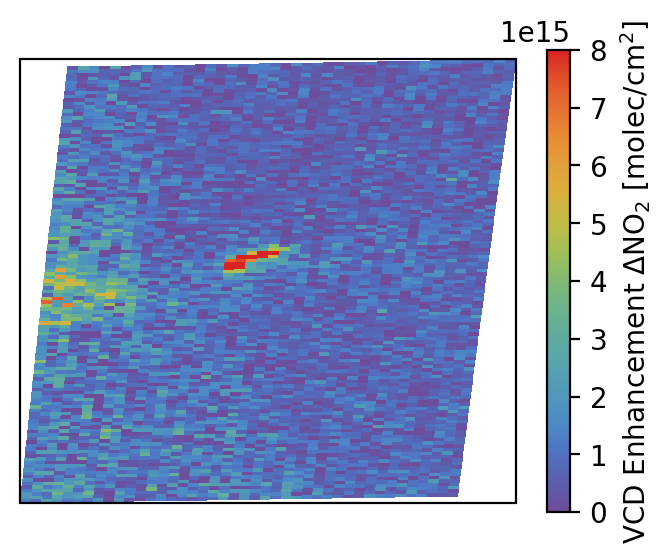

In [17]:
fig, ax = plt.subplots(figsize=(4,3), dpi=200, subplot_kw={'projection': ccrs.PlateCarree(),})
plot_TEMPO_L2(ds.isel(time=4), ax=ax, vmin=0, vmax=8e15, cmap=tc.tol_cmap("rainbow_PuRd"), show_colorbar=True)
# Colorbar is typically the second axis created in the figure
cax = fig.axes[-1]
cax.set_ylabel(r"VCD Enhancement $\Delta$NO$_2$ [molec/cm$^2$]")

Text(0, 0.5, 'Tropospheric AMF')

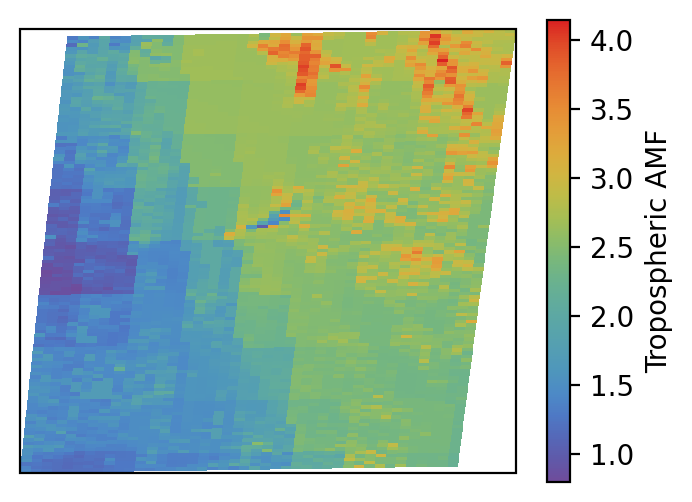

In [18]:
fig, ax = plt.subplots(figsize=(4,3), dpi=200, subplot_kw={'projection': ccrs.PlateCarree(),})
plot_TEMPO_L2(ds.isel(time=4), quantity="amf_troposphere", ax=ax, cmap=tc.tol_cmap("rainbow_PuRd"), show_colorbar=True)
# Colorbar is typically the second axis created in the figure
cax = fig.axes[-1]
cax.set_ylabel("Tropospheric AMF")

Text(0, 0.5, 'Effective Cloud Fraction')

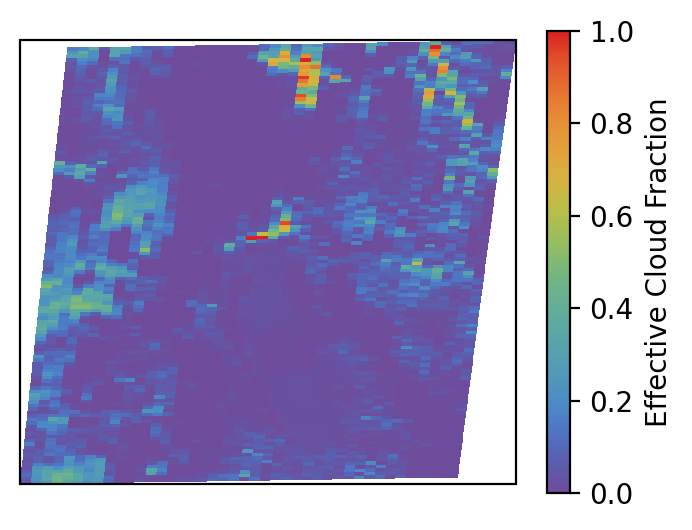

In [19]:
fig, ax = plt.subplots(figsize=(4,3), dpi=200, subplot_kw={'projection': ccrs.PlateCarree(),})
plot_TEMPO_L2(ds.isel(time=4), quantity="eff_cloud_fraction", ax=ax, vmin=0, vmax=1, cmap=tc.tol_cmap("rainbow_PuRd"), show_colorbar=True)
# Colorbar is typically the second axis created in the figure
cax = fig.axes[-1]
cax.set_ylabel("Effective Cloud Fraction")

Text(0, 0.5, 'Stratospheric AMF')

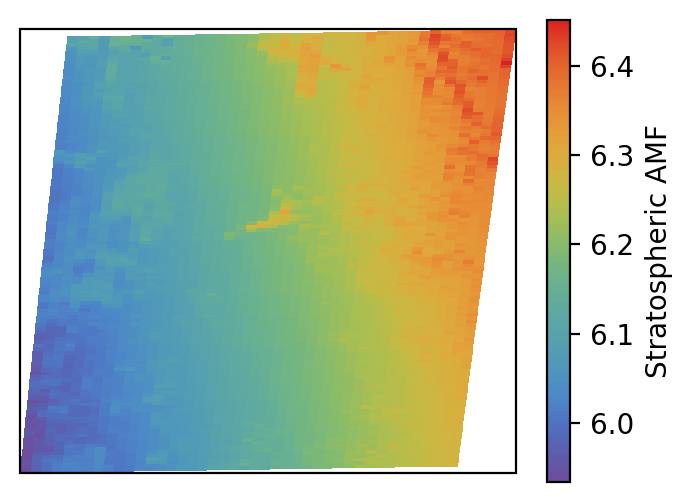

In [20]:
fig, ax = plt.subplots(figsize=(4,3), dpi=200, subplot_kw={'projection': ccrs.PlateCarree(),})
plot_TEMPO_L2(ds.isel(time=4), quantity="amf_stratosphere", ax=ax, cmap=tc.tol_cmap("rainbow_PuRd"), show_colorbar=True)
# Colorbar is typically the second axis created in the figure
cax = fig.axes[-1]
cax.set_ylabel("Stratospheric AMF")

Text(0, 0.5, 'Total AMF')

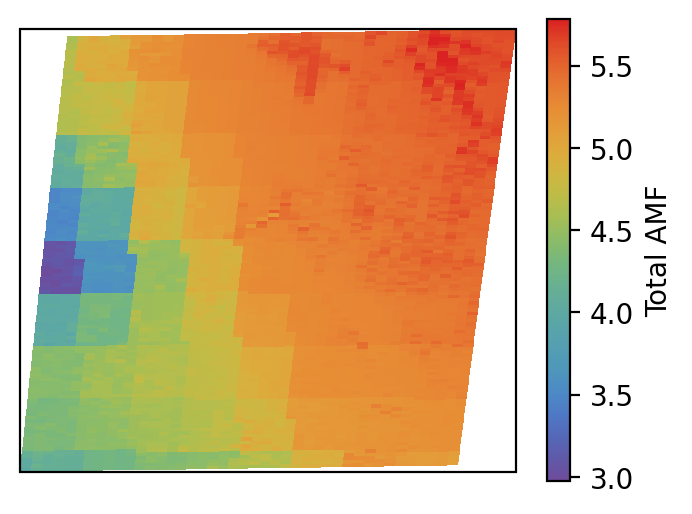

In [21]:
fig, ax = plt.subplots(figsize=(4,3), dpi=200, subplot_kw={'projection': ccrs.PlateCarree(),})
plot_TEMPO_L2(ds.isel(time=3), quantity="amf_total", ax=ax, cmap=tc.tol_cmap("rainbow_PuRd"), show_colorbar=True)
# Colorbar is typically the second axis created in the figure
cax = fig.axes[-1]
cax.set_ylabel("Total AMF")

Text(0, 0.5, 'Fitted Slant Column')

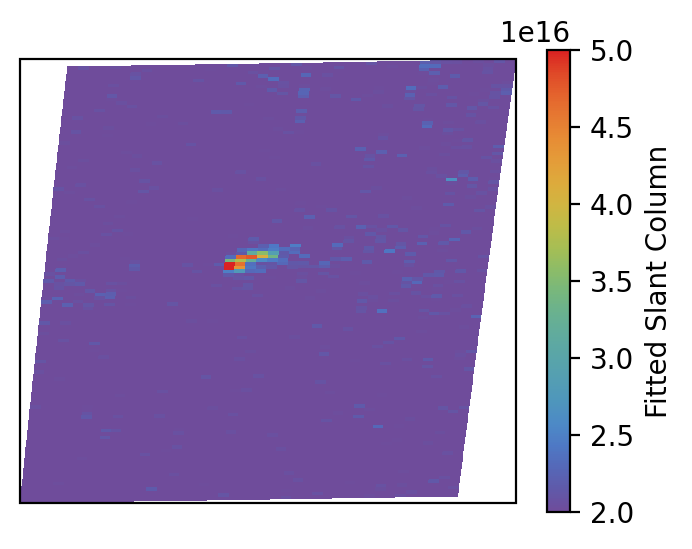

In [22]:
fig, ax = plt.subplots(figsize=(4,3), dpi=200, subplot_kw={'projection': ccrs.PlateCarree(),})
plot_TEMPO_L2(ds.isel(time=4), quantity="slant_column", vmin=2e16, vmax=5e16, ax=ax, cmap=tc.tol_cmap("rainbow_PuRd"), show_colorbar=True)
# Colorbar is typically the second axis created in the figure
cax = fig.axes[-1]
cax.set_ylabel("Fitted Slant Column")

In [23]:
ds["amf_geometric"] = (
    1 / np.cos(np.deg2rad(ds["solar_zenith_angle"]))
    + 1 / np.cos(np.deg2rad(ds["viewing_zenith_angle"]))
)

Text(0, 0.5, 'Geometric AMF')

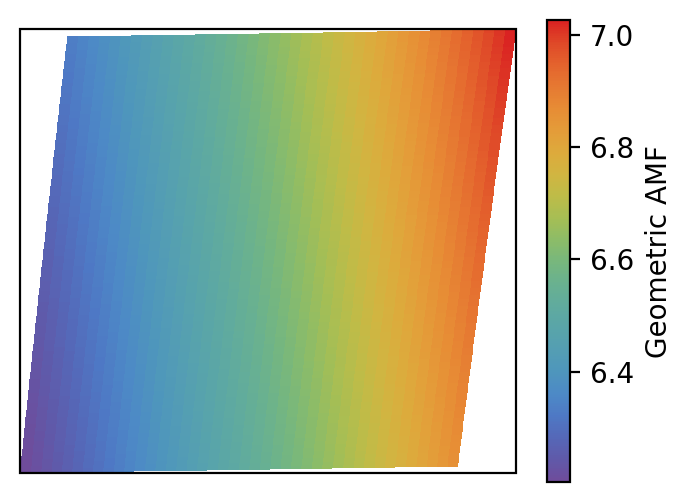

In [24]:
fig, ax = plt.subplots(figsize=(4,3), dpi=200, subplot_kw={'projection': ccrs.PlateCarree(),})
plot_TEMPO_L2(ds.isel(time=4), quantity="amf_geometric", ax=ax, cmap=tc.tol_cmap("rainbow_PuRd"), show_colorbar=True)
# Colorbar is typically the second axis created in the figure
cax = fig.axes[-1]
cax.set_ylabel("Geometric AMF")

In [25]:
sc = ds["slant_column"]

# Spatial 10th percentile independently for each TEMPO scan
background = sc.quantile(
    0.1,
    dim=["y", "x"],
    skipna=True
)

ds["slant_column_enhancement"] = sc - background

Text(0, 0.5, 'Slant Column Enhancement')

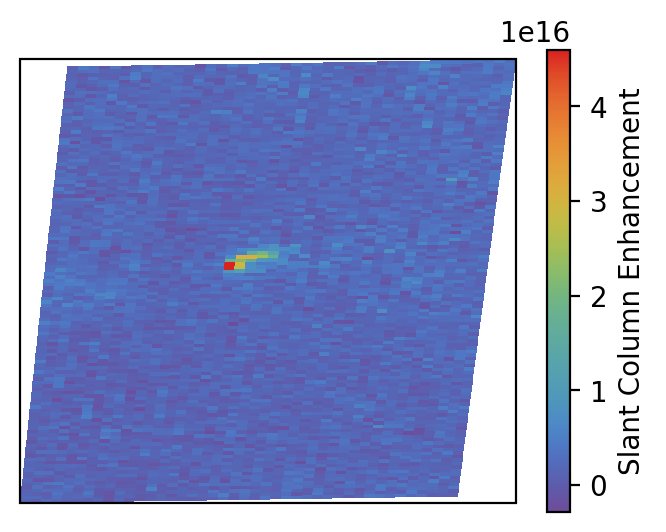

In [26]:

fig, ax = plt.subplots(
    figsize=(4, 3),
    dpi=200,
    subplot_kw={"projection": ccrs.PlateCarree()}
)

plot_TEMPO_L2(
    ds.isel(time=4),
    quantity="slant_column_enhancement",
    ax=ax,
    cmap=tc.tol_cmap("rainbow_PuRd"),
    show_colorbar=True
)

cax = fig.axes[-1]
cax.set_ylabel("Slant Column Enhancement")

Text(0, 0.5, 'Geometric VCD')

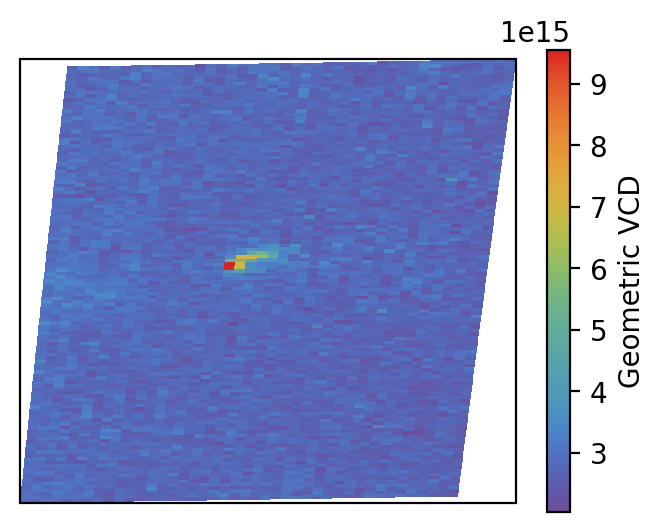

In [27]:
ds['vcd_geometric'] = ds['slant_column'] / ds['amf_geometric']
fig, ax = plt.subplots(figsize=(4,3), dpi=200, subplot_kw={'projection': ccrs.PlateCarree(),})
plot_TEMPO_L2(ds.isel(time=4), quantity="vcd_geometric", ax=ax, cmap=tc.tol_cmap("rainbow_PuRd"), show_colorbar=True)
# Colorbar is typically the second axis created in the figure
cax = fig.axes[-1]
cax.set_ylabel("Geometric VCD")

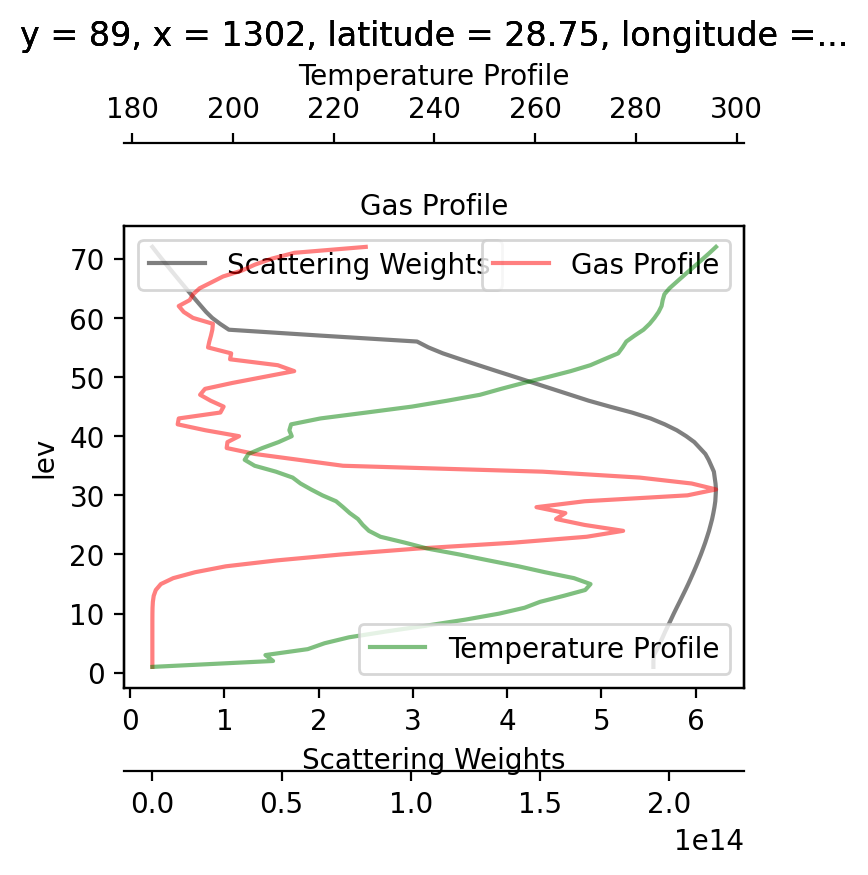

In [28]:
fig, ax = plt.subplots(figsize=(4,3), dpi=200,)
ds.isel(time=4, y=30, x=50)['scattering_weights'].plot(y='lev', ax=ax, color='k', alpha=0.5, label='Scattering Weights')
ax1 = ax.twiny()
ds.isel(time=4, y=30, x=50)['gas_profile'].plot(y='lev', ax=ax1, color='r', alpha=0.5, label='Gas Profile')
ax.set_xlabel("Scattering Weights")
# make ax1 on top spine
ax1.spines['bottom'].set_position(('outward', 30))
ax1.set_xlabel("Gas Profile")
ax2 = ax1.twiny()
ds.isel(time=4, y=30, x=50)['temperature_profile'].plot(y='lev', ax=ax2, color='g', alpha=0.5, label='Temperature Profile')
# move the temperature axis
ax2.spines['top'].set_position(('outward', 30))
ax2.set_xlabel("Temperature Profile")
# full single legend
ax.legend(loc='upper left')
ax1.legend(loc='upper right')
ax2.legend(loc='lower right')


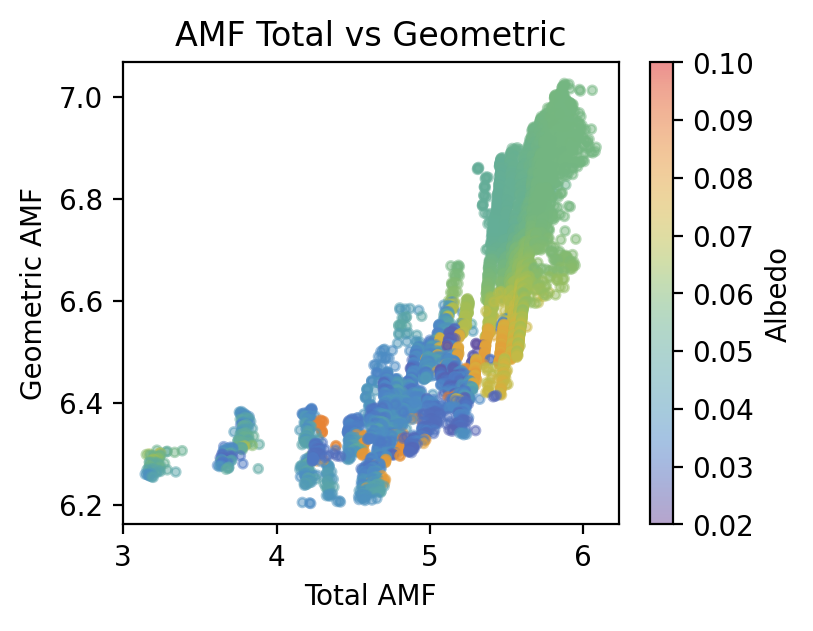

In [29]:
fig, ax = plt.subplots(figsize=(4,3), dpi=200,)
p = ax.scatter(ds.isel(time=4,)['amf_total'].values, ds.isel(time=4,)['amf_geometric'].values, c=ds.isel(time=4,)['albedo'].values, cmap=tc.tol_cmap("rainbow_PuRd"), vmin=0.02, vmax=0.1, s=10, alpha=0.5)
# ax.plot(np.linspace(3, 7.5, 100), np.linspace(3, 7.5, 100), color='k', alpha=0.5)
ax.set_xlabel("Total AMF")
ax.set_ylabel("Geometric AMF")
ax.set_title("AMF Total vs Geometric")
fig.colorbar(p, ax=ax, label="Albedo")

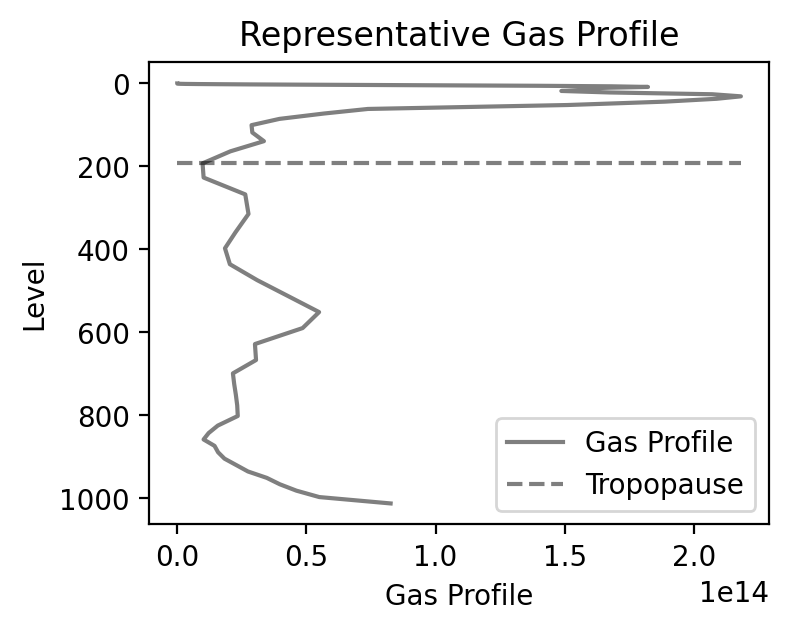

In [30]:
# representative gas profile for rocket launch
tmp_ds = ds.isel(time=4, y=30, x=50)
fig, ax = plt.subplots(figsize=(4,3), dpi=200,)
ax.plot(tmp_ds['gas_profile'].values, tmp_ds['pressure_levels'].values, color='k', alpha=0.5, label='Gas Profile')
ax.hlines(tmp_ds["tropopause_pressure"].values, 0, np.max(tmp_ds['gas_profile'].values), color='k', linestyle='--', alpha=0.5, label='Tropopause')
ax.invert_yaxis()
ax.set_xlabel("Gas Profile")
ax.set_ylabel("Level")
ax.set_title("Representative Gas Profile")
ax.legend()

In [31]:
pix = ds.isel(time=4, y=30, x=50).load()
p = pix["pressure_levels"].values          # hPa; index 0 = top of atmosphere
w = pix["scattering_weights"].values
T = pix["temperature_profile"].values      # K
g = pix["gas_profile"].values              # molec cm^-2
p_trop = float(pix["tropopause_pressure"])

def temperature_factor(T):
    dT = T - 220.0
    return 1.0 - 0.00316 * dT + 3.39e-6 * dT**2

def amf(partial_column, w, T):
    x = np.asarray(partial_column, dtype=float)
    x = np.where(np.isfinite(x), x, 0.0)
    shape = x / x.sum()                    # the shape factor
    return np.sum(w * temperature_factor(T) * shape)

# a priori troposphere: the right baseline for a plume enhancement
g_trop = np.where(p >= p_trop, g, 0.0)
amf_trop = amf(g_trop, w, T)

In [32]:
pix['amf_troposphere'].values, amf_trop

(array(1.9415811, dtype=float32), 1.9415811300589552)

In [33]:
f9 = pd.read_csv("data/Falcon9-traj-emissions.csv")
nox = f9["NOX-kg"].to_numpy()[::-1]       # CSV is surface-first; ds is TOA-first
nox = np.where(p >= p_trop, nox, 0.0)
amf_rocket = amf(nox, w, T)

In [34]:
amf_rocket

1.9471606077712915

In [35]:
z_km = f9["Altitude-m"].to_numpy()[::-1] / 1000.0
dz = np.diff(z_km, prepend=z_km[0] - (z_km[1] - z_km[0]))

def gaussian_layer_mass(z_km, dz, z0_km, sigma_km):
    return np.exp(-0.5 * ((z_km - z0_km) / sigma_km) ** 2) * np.abs(dz)

for z0 in (1, 5, 10, 15):
    mass = gaussian_layer_mass(z_km, dz, z0, sigma_km=1.0)
    mass = np.where(p >= p_trop, mass, 0.0)
    print(z0, amf(mass, w, T))

1 0.6417594522019245
5 3.2729262940592947
10 5.029673214008326
15 5.564116209775886


background column 3708984200000000.0
plume / background 0.10784623883596263
AMF background total 5.143784359151998
AMF plume only 3.2729262940595234
AMF background + plume 4.961660697727586
AMF trop. background 1.9415811300589552
AMF trop. background + plume 2.360460729981501


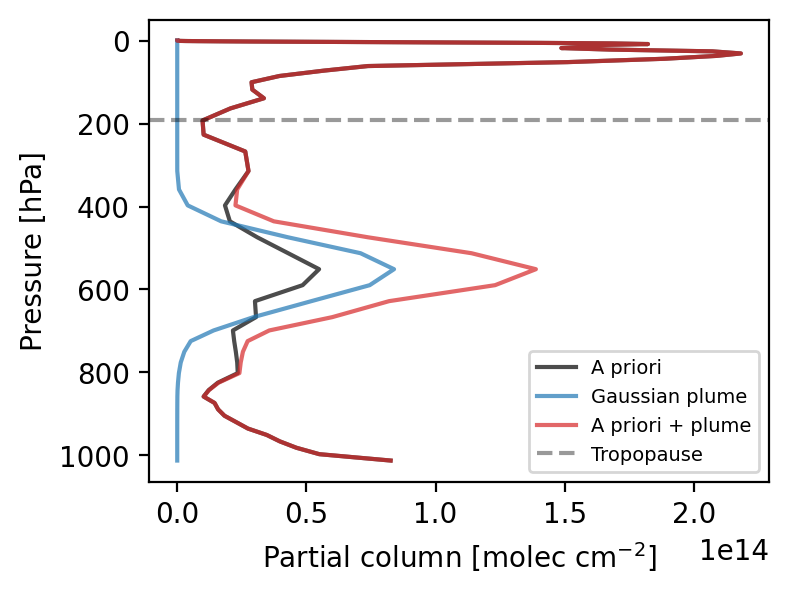

In [36]:
# Add a Gaussian plume onto the a priori partial-column profile.
# gaussian_layer_mass is only relative; scale it so the layers sum to a
# plume vertical column in molec cm^-2, then add layer by layer.
plume_vcd = 4e14  # molec cm^-2
z0_km = 5.0
sigma_km = 1.0

mass = gaussian_layer_mass(z_km, dz, z0_km, sigma_km)
shape = mass / mass.sum()
plume_partial = plume_vcd * shape
g_plus = g + plume_partial

# Same plume added only onto the tropospheric a priori.
# Layers above the tropopause keep the background and none of the plume.
g_trop_plus = np.where(p >= p_trop, g + plume_partial, 0.0)

print("background column", g.sum())
print("plume / background", plume_vcd / g.sum())
print("AMF background total", amf(g, w, T))
print("AMF plume only", amf(plume_partial, w, T))
print("AMF background + plume", amf(g_plus, w, T))
print("AMF trop. background", amf_trop)
print("AMF trop. background + plume", amf(g_trop_plus, w, T))

fig, ax = plt.subplots(figsize=(4, 3), dpi=200)
ax.plot(g, p, color="k", alpha=0.7, label="A priori")
ax.plot(plume_partial, p, color="C0", alpha=0.7, label="Gaussian plume")
ax.plot(g_plus, p, color="C3", alpha=0.7, label="A priori + plume")
ax.axhline(p_trop, color="k", ls="--", alpha=0.4, label="Tropopause")
ax.invert_yaxis()
ax.set_xlabel(r"Partial column [molec cm$^{-2}$]")
ax.set_ylabel("Pressure [hPa]")
ax.legend(fontsize=7)


21 plume pixels
AMF E(z) median 2.080
AMF file troposphere median 2.696
VCD enhancement median 9.081e+15 molec cm^-2
VCD ratio, E(z) / file trop AMF 1.304


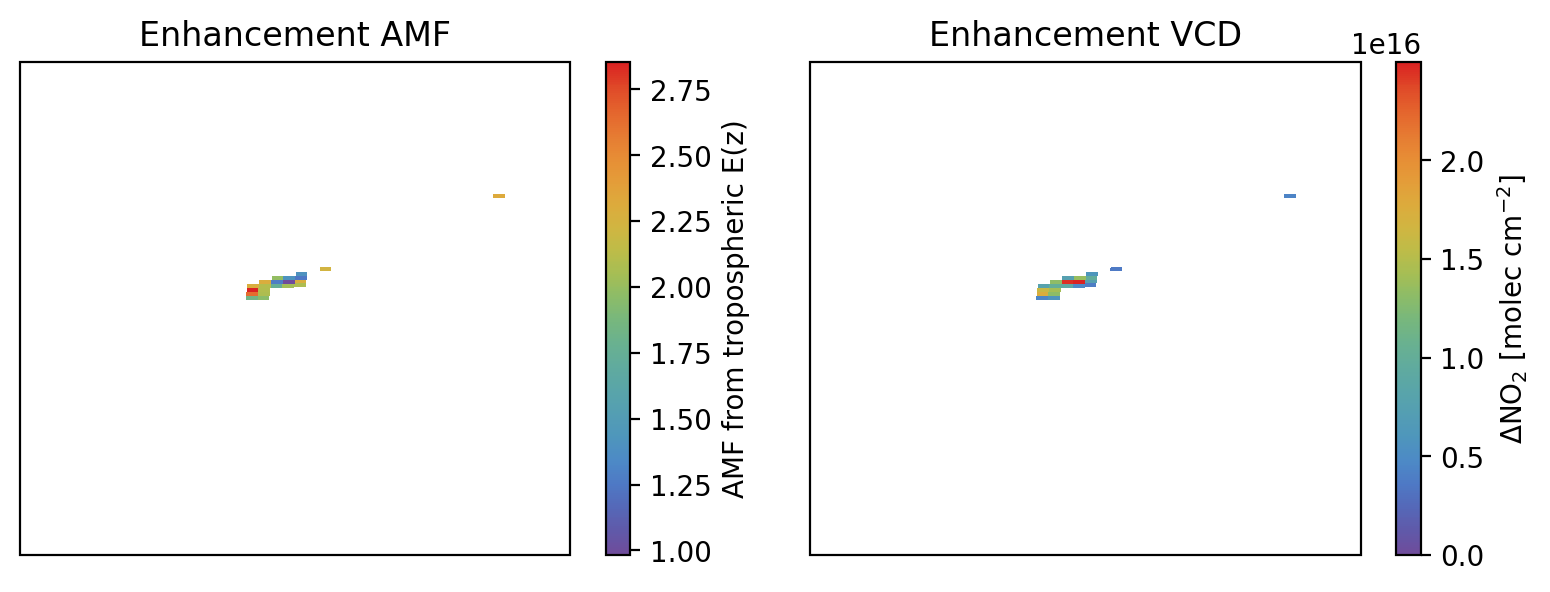

In [37]:
# Enhancement AMF from the tropospheric Falcon 9 E(z) shape.
# The shape is the same ascent profile for every pixel; scattering weights,
# temperature, and the tropopause are the pixel's own.
scan = ds.isel(time=4).load()

e_z = xr.DataArray(
    f9["NOX-kg"].to_numpy()[::-1],
    dims=("lev",),
    coords={"lev": scan["lev"]},
)
e_trop = xr.where(scan["pressure_levels"] >= scan["tropopause_pressure"], e_z, 0.0)
shape = e_trop / e_trop.sum("lev")
tf = temperature_factor(scan["temperature_profile"])

scan["amf_ez"] = (scan["scattering_weights"] * tf * shape).sum("lev")
scan["vcd_enhancement_ez"] = scan["slant_column_enhancement"] / scan["amf_ez"]
scan["vcd_enhancement_trop"] = scan["slant_column_enhancement"] / scan["amf_troposphere"]

# Upper tail of the slant-column enhancement in this scan.
plume = scan["slant_column_enhancement"] > scan["slant_column_enhancement"].quantile(0.996)
scan["amf_ez"] = scan["amf_ez"].where(plume)
scan["vcd_enhancement_ez"] = scan["vcd_enhancement_ez"].where(plume)
scan["vcd_enhancement_trop"] = scan["vcd_enhancement_trop"].where(plume)

print(f"{int(plume.sum())} plume pixels")
print(f"AMF E(z) median {float(scan['amf_ez'].median()):.3f}")
print(f"AMF file troposphere median {float(scan['amf_troposphere'].where(plume).median()):.3f}")
print(f"VCD enhancement median {float(scan['vcd_enhancement_ez'].median()):.3e} molec cm^-2")
print(
    "VCD ratio, E(z) / file trop AMF "
    f"{float((scan['vcd_enhancement_ez'] / scan['vcd_enhancement_trop']).median()):.3f}"
)

fig, axes = plt.subplots(
    1, 2, figsize=(8, 3), dpi=200,
    subplot_kw={"projection": ccrs.PlateCarree()},
)
plot_TEMPO_L2(scan, quantity="amf_ez", ax=axes[0], cmap=tc.tol_cmap("rainbow_PuRd"))
axes[0].set_title("Enhancement AMF")
fig.axes[-1].set_ylabel("AMF from tropospheric E(z)")

plot_TEMPO_L2(
    scan, quantity="vcd_enhancement_ez", ax=axes[1],
    cmap=tc.tol_cmap("rainbow_PuRd"), vmin=0,
)
axes[1].set_title(r"Enhancement VCD")
fig.axes[-1].set_ylabel(r"$\Delta$NO$_2$ [molec cm$^{-2}$]")
fig.tight_layout()


In [38]:
len(ds.time)

13

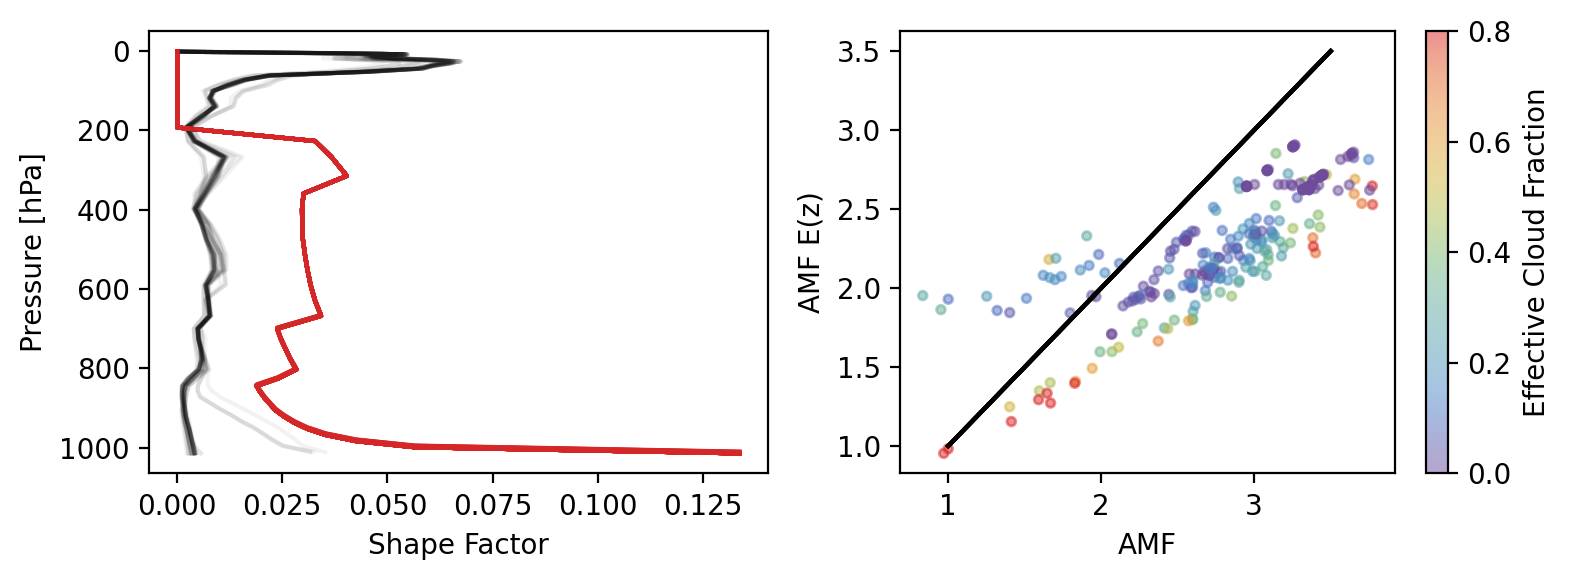

In [39]:
fig,axs = plt.subplots(1,2, figsize=(8,3), dpi=200,)
for i in range(len(ds.time)):
    scan = ds.isel(time=i).load()

    e_z = xr.DataArray(
        f9["NOX-kg"].to_numpy()[::-1],
        dims=("lev",),
        coords={"lev": scan["lev"]},
    )
    e_trop = xr.where(scan["pressure_levels"] >= scan["tropopause_pressure"], e_z, 0.0)
    shape = e_trop / e_trop.sum("lev")
    scan["shape"] = shape
    tf = temperature_factor(scan["temperature_profile"])

    scan["amf_ez"] = (scan["scattering_weights"] * tf * shape).sum("lev")

    # Upper tail of the slant-column enhancement in this scan.
    plume = scan["slant_column_enhancement"] > scan["slant_column_enhancement"].quantile(0.996)
    scan["amf_ez"] = scan["amf_ez"].where(plume)
    scan["gas_profile"] = scan["gas_profile"].where(plume)
    scan["pressure_levels"] = scan["pressure_levels"].where(plume)

    # # plot the shape and the gas profile for every pixel in scan
    for j in range(len(scan['latitude'])):
        for k in range(len(scan['longitude'])):
            tmp_shape = scan['shape'].isel(y=j, x=k).values
            tmp_gas_profile = (scan['gas_profile'].isel(y=j, x=k) / scan['gas_profile'].isel(y=j, x=k).sum('lev')).values
            tmp_pressure_levels = scan['pressure_levels'].isel(y=j, x=k).values
            axs[0].plot(tmp_shape, tmp_pressure_levels, color='tab:red', alpha=0.9)
            axs[0].plot(tmp_gas_profile, tmp_pressure_levels, color='k', alpha=0.05)

    p = axs[1].scatter(scan['amf_troposphere'].values, scan['amf_ez'].values, c=scan['eff_cloud_fraction'].values, cmap=tc.tol_cmap("rainbow_PuRd"), vmin=0, vmax=0.8, s=10, alpha=0.5)
    # one to one line
    axs[1].plot(np.linspace(1.0, 3.5, 100), np.linspace(1.0, 3.5, 100), color='k', alpha=0.5)

axs[0].set_xlabel("Shape Factor")
axs[0].set_ylabel("Pressure [hPa]")
axs[0].invert_yaxis()

axs[1].set_xlabel("AMF")
axs[1].set_ylabel("AMF E(z)")
fig.colorbar(p, ax=axs[1], label="Effective Cloud Fraction")
fig.tight_layout()



time 3: 39 saved plume pixels
time 4: 46 saved plume pixels
time 5: 50 saved plume pixels
time 6: 52 saved plume pixels
time 7: 67 saved plume pixels
time 8: 65 saved plume pixels
time 9: 40 saved plume pixels
time 10: 28 saved plume pixels
time 11: 30 saved plume pixels


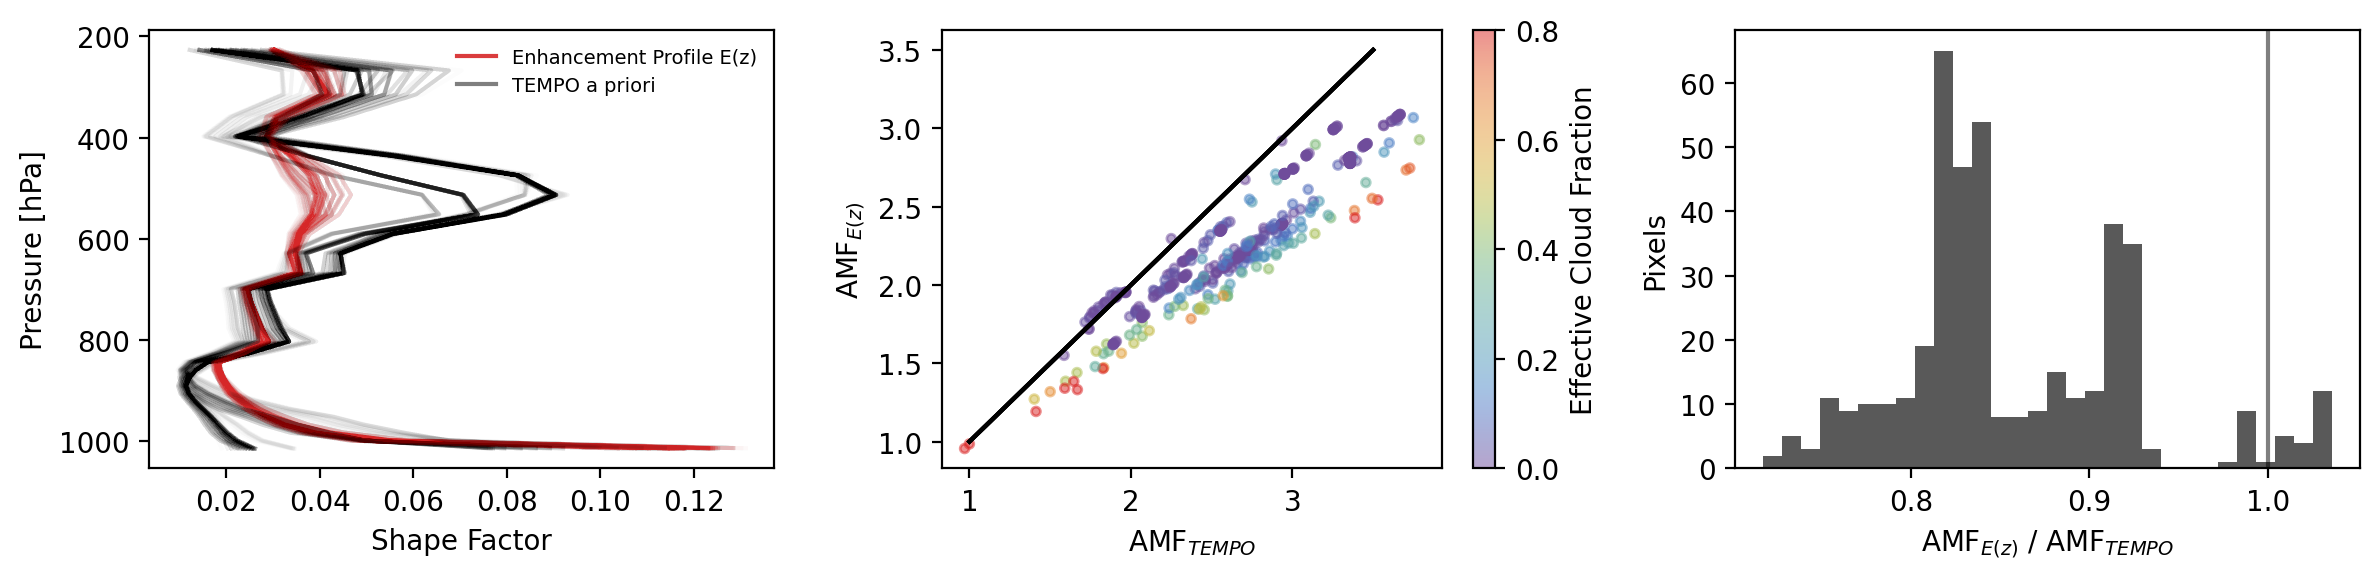

In [45]:
saved_plumes = [
    xr.open_dataarray(f)
    for f in sorted(glob.glob("artemis_launch/plumes/20260401T22_hour*.nc"))
]

def saved_plume_mask(scan):
    """Nonzero pixels from the saved plume file whose scanline time matches this scan."""
    for da in saved_plumes:
        y_ref = int(da.y.values[len(da.y) // 2])
        if y_ref not in scan.y.values:
            continue
        dt = abs(scan.lat_time.sel(y=y_ref).values - da.lat_time.sel(y=y_ref).values)
        if dt > np.timedelta64(1, "s"):
            continue
        return (da != 0).reindex(y=scan.y, x=scan.x).fillna(False)
    return None

fig, axs = plt.subplots(1, 3, figsize=(12, 3), dpi=200)
ratios = []
for i in range(len(ds.time)):
    scan = ds.isel(time=i).load()

    plume = saved_plume_mask(scan)
    if plume is None or not bool(plume.any()):
        continue
    print(f"time {i}: {int(plume.sum())} saved plume pixels")

    e_z = xr.DataArray(
        f9["NOX-kg"].to_numpy()[::-1],
        dims=("lev",),
        coords={"lev": scan["lev"]},
    )
    e_trop = xr.where(scan["pressure_levels"] >= scan["tropopause_pressure"], e_z, 0.0)
    # weight the e_z by the mean vcd enhancement within the plume, and the background gas profile by the mean vcd enhancement outside the plume
    mean_plume_vcd_enhancement = scan["vertical_column_troposphere"].where(plume.astype(bool)).mean()
    mean_background_vcd_enhancement = scan["vertical_column_troposphere"].where(~plume.astype(bool)).mean()
    mean_apriori_vcd_enhancement = scan["gas_profile"].sum("lev").where(~plume.astype(bool)).mean()

    # print(f"plume to background vcd enhancement ratio: {mean_plume_vcd_enhancement / mean_background_vcd_enhancement}")
    # print(f"plume to a priori background vcd enhancement ratio: {mean_plume_vcd_enhancement / mean_apriori_vcd_enhancement}")

    plume_to_background_ratio = (mean_plume_vcd_enhancement / (mean_plume_vcd_enhancement + mean_background_vcd_enhancement)).values
    # plume_to_background_ratio = (mean_plume_vcd_enhancement / (mean_plume_vcd_enhancement + mean_apriori_vcd_enhancement)).values
    # linear combination -- weight e_trop by mean_plume_vcd_enhancement and scan["gas_profile"] by mean_background_vcd_enhancement, then combine
    # e_trop = e_trop * mean_plume_vcd_enhancement
    # scan["gas_profile"] = scan["gas_profile"] * mean_background_vcd_enhancement
    # e_trop = e_trop + scan["gas_profile"]

    shape = e_trop / e_trop.sum("lev")
    scan["shape"] = shape
    tf = temperature_factor(scan["temperature_profile"])

    # nans, but same shape as scan["amf_troposphere"]
    scan["amf_ez"] = xr.full_like(scan["amf_troposphere"], np.nan)

    # scan["amf_ez"] = (scan["scattering_weights"] * tf * shape).sum("lev")
    # scan["amf_ez"] = scan["amf_ez"].where(plume)
    scan["gas_profile"] = scan["gas_profile"].where(plume)
    scan["pressure_levels"] = scan["pressure_levels"].where(plume)

    # ratio = (scan["amf_ez"] / scan["amf_troposphere"]).values
    # ratios.append(ratio[np.isfinite(ratio)])

    for j, k in zip(*np.where(plume.values)):
        tmp_shape = scan["shape"].isel(y=j, x=k).values
        # replace 0 with np.nan in tmp_shape
        tmp_shape = np.where(tmp_shape == 0, np.nan, tmp_shape)
        g = scan["gas_profile"].isel(y=j, x=k)
        p_lev = scan["pressure_levels"].isel(y=j, x=k)
        g_trop = g.where(p_lev >= scan["tropopause_pressure"].isel(y=j, x=k))
        tmp_gas_profile = (g_trop / g_trop.sum("lev")).values

        # weight the gas profile by the plume to background vcd enhancement ratio
        tmp_shape_weighted = (tmp_shape * plume_to_background_ratio) + ((1 - plume_to_background_ratio) * tmp_gas_profile)
        tmp_pressure_levels = p_lev.values

        # axs[0].plot(tmp_shape, tmp_pressure_levels, color="tab:red", alpha=0.9)
        axs[0].plot(tmp_shape_weighted, tmp_pressure_levels, color="tab:red", alpha=0.01)
        axs[0].plot(tmp_gas_profile, tmp_pressure_levels, color="k", alpha=0.01)

        # calculate the amf of the weighted shape
        tf = temperature_factor(scan["temperature_profile"].isel(y=j, x=k))
        amf_weighted = (scan["scattering_weights"].isel(y=j, x=k) * tf * tmp_shape_weighted).sum("lev")
        amf_troposphere = scan["amf_troposphere"].isel(y=j, x=k)
        ratio = amf_weighted / amf_troposphere
        ratios.append(ratio)

        # save to amf_ez in scan
        scan["amf_ez"][dict(y=j, x=k)] = amf_weighted
        
    p = axs[1].scatter(
        scan["amf_troposphere"].values,
        scan["amf_ez"].values,
        c=scan["eff_cloud_fraction"].values,
        cmap=tc.tol_cmap("rainbow_PuRd"),
        vmin=0, vmax=0.8, s=10, alpha=0.5,
    )
    axs[1].plot(np.linspace(1.0, 3.5, 100), np.linspace(1.0, 3.5, 100), color="k", alpha=0.5)

# ratios = np.concatenate(ratios)
axs[2].hist(ratios, bins=30, color="0.35")
axs[2].axvline(1.0, color="k", alpha=0.5)
# axs[2].axvline(np.median(ratios), color="tab:red", alpha=0.8)
axs[2].set_xlabel(r"AMF$_{E(z)}$ / AMF$_{TEMPO}$")
axs[2].set_ylabel("Pixels")

axs[0].plot([], [], color="tab:red", alpha=0.9, label="Enhancement Profile E(z)")
axs[0].plot([], [], color="k", alpha=0.5, label="TEMPO a priori")
axs[0].legend(loc="upper right", frameon=False, fontsize=7)
axs[0].set_xlabel("Shape Factor")
axs[0].set_ylabel("Pressure [hPa]")
axs[0].invert_yaxis()

axs[1].set_xlabel(r"AMF$_{TEMPO}$")
axs[1].set_ylabel(r"AMF$_{E(z)}$")
fig.colorbar(p, ax=axs[1], label="Effective Cloud Fraction")
fig.tight_layout()
plt.savefig(f'figures/fig_S4.png', dpi=300)
plt.savefig(f'figures/fig_S4.pdf', dpi=300)

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1800, 1200) to (1808, 1200) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
[rawvideo @ 0x573f700] Stream #0: not enough frames to estimate rate; consider increasing probesize


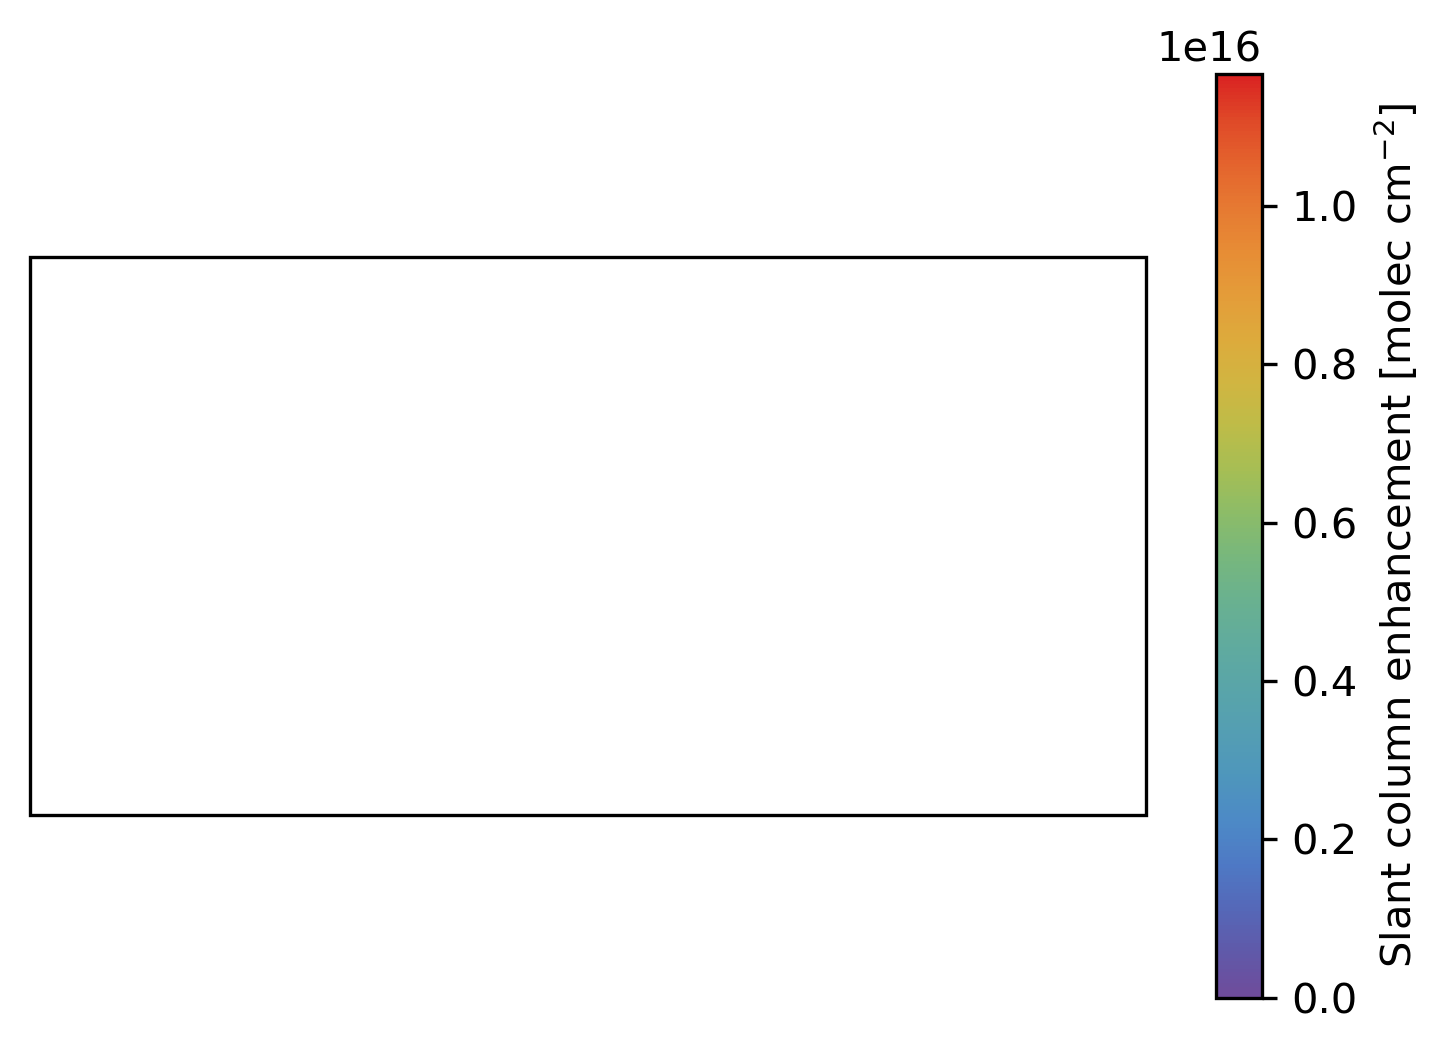

In [41]:
outdir = "artemis_launch/slant_column"
os.makedirs(f"{outdir}/frames", exist_ok=True)

# One scale for the whole video. 0.99 keeps the plume from saturating.
vmax = float(ds["slant_column_enhancement"].load().quantile(0.99, skipna=True))

figure, ax = plt.subplots(figsize=(6, 4), subplot_kw={"projection": ccrs.PlateCarree()}, dpi=300)
make_cbar = True
for i, t in enumerate(ds.time):
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="grey", linewidth=1)
    ax.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="grey", linewidth=0.5)

    plot_TEMPO_L2(
        ds.isel(time=i),
        quantity="slant_column_enhancement",
        ax=ax,
        vmin=0,
        vmax=vmax,
        cmap=tc.tol_cmap("rainbow_PuRd"),
        show_colorbar=make_cbar,
    )
    if make_cbar:
        figure.axes[-1].set_ylabel(r"Slant column enhancement [molec cm$^{-2}$]")
        make_cbar = False

    timestamp = pd.to_datetime(ds.time.values[i]).round("min")
    ax.set_title(timestamp.strftime("%Y-%m-%d %H:%M"))
    ax.scatter([-80.6819], [28.5233], marker="*", edgecolor="black", color="grey", linewidth=0.5, s=50)
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

    plume_file = f"artemis_launch/plumes/20260401T22_hour{i}.nc"
    if os.path.exists(plume_file):
        plume = xr.open_dataarray(plume_file)
        mask = plume.values.astype(float)
        mask[~np.isfinite(mask)] = 0.0
        ax.contour(
            plume["longitude"].values,
            plume["latitude"].values,
            mask,
            levels=[0.5],
            colors="k",
            linewidths=0.5,
            transform=ccrs.PlateCarree(),
            zorder=10,
        )

    stamp = str(ds.time.values[i]).replace(":", "").replace(".", "")
    plt.savefig(f"{outdir}/frames/{stamp}.png")
    ax.cla()

filenames = sorted(glob.glob(f"{outdir}/frames/*.png"))
imageio.mimsave(f"{outdir}/output.mp4", [imageio.imread(f) for f in filenames], fps=1)

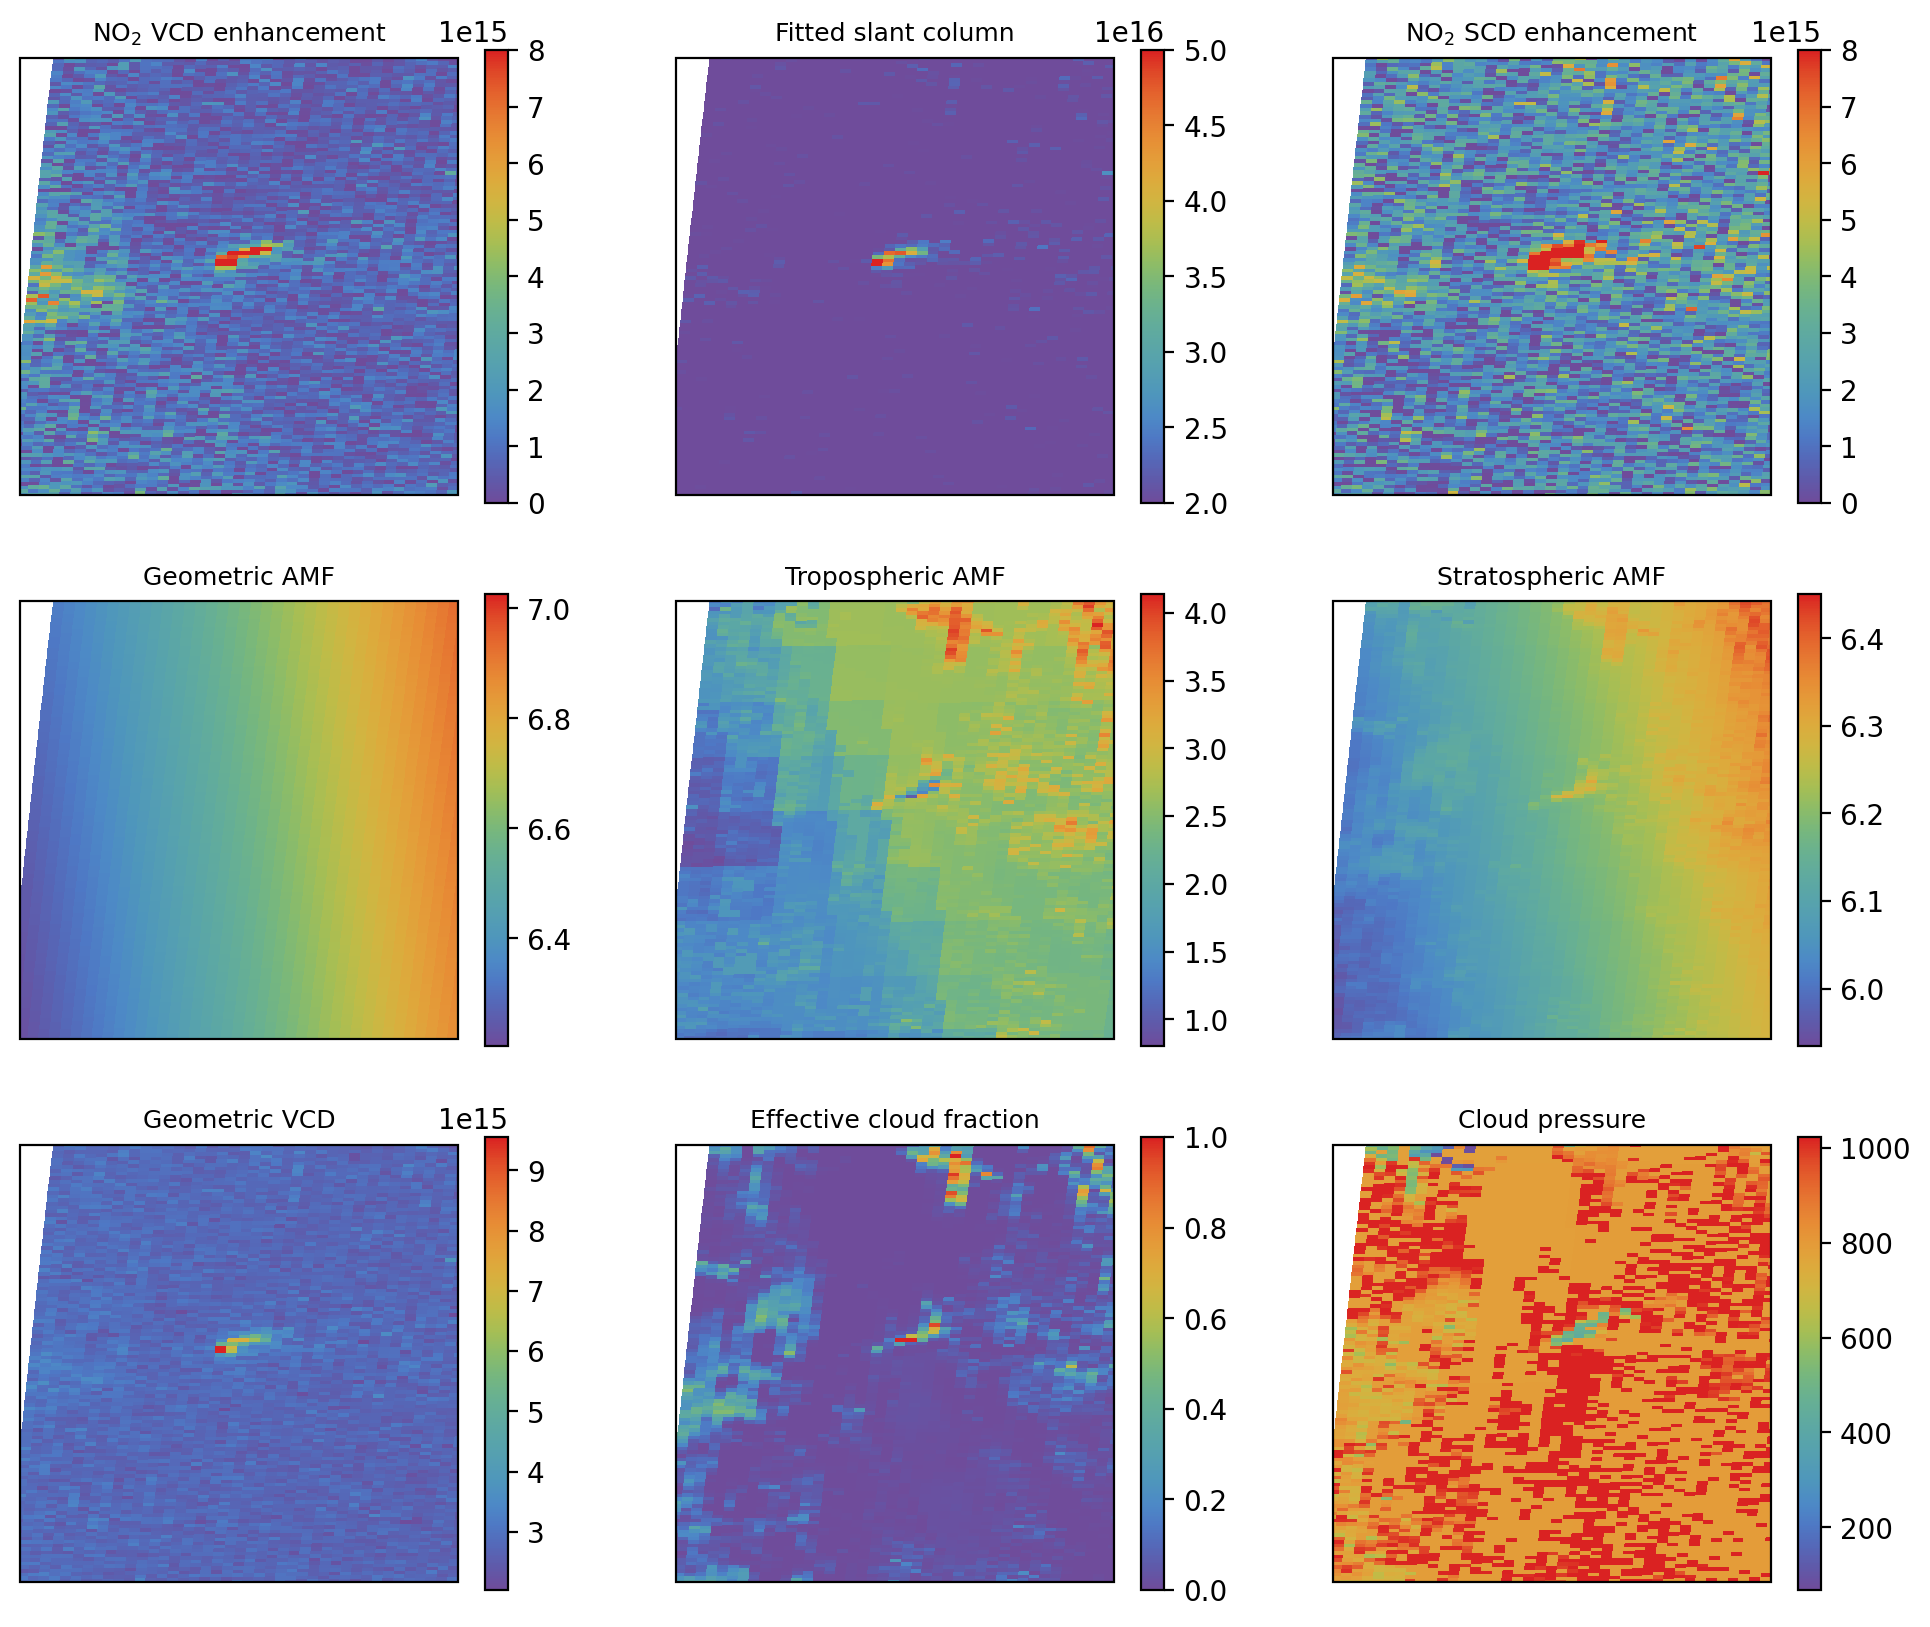

In [46]:
scan = ds.isel(time=4).load()
sc_vmax = float(scan["slant_column_enhancement"].quantile(0.99, skipna=True))

panels = [
    ("vertical_column_troposphere", r"NO$_2$ VCD enhancement", {"vmin": 0, "vmax": 8e15}),
    ("slant_column", "Fitted slant column", {"vmin": 2e16, "vmax": 5e16}),
    ("slant_column_enhancement", r"NO$_2$ SCD enhancement", {"vmin": 0, "vmax": 8e15}),
    ("amf_geometric", "Geometric AMF", {}),
    ("amf_troposphere", "Tropospheric AMF", {}),
    ("amf_stratosphere", "Stratospheric AMF", {}),
    ("vcd_geometric", "Geometric VCD", {}),
    ("eff_cloud_fraction", "Effective cloud fraction", {"vmin": 0, "vmax": 1}),
    ("cloud_pressure", "Cloud pressure", {}),
]

fig, axes = plt.subplots(
    3, 3, figsize=(12, 10), dpi=200,
    subplot_kw={"projection": ccrs.PlateCarree()},
    # constrained_layout=True,
)

for ax, (quantity, label, limits) in zip(axes.ravel(), panels):
    plot_TEMPO_L2(
        scan, quantity=quantity, ax=ax,
        cmap=tc.tol_cmap("rainbow_PuRd"), show_colorbar=True, **limits,
    )
    ax.set_title(label, fontsize=9)
    fig.axes[-1].set_ylabel("")
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
# fig.tight_layout()
plt.savefig(f'figures/fig_S3.png', dpi=300)
plt.savefig(f'figures/fig_S3.pdf', dpi=300)